# CR04 - Reason codes for a scorecard (German Credit)

Goal: explain each applicant's score. For each holdout applicant, the top-3 features that pull
the points down relative to the best bin of each feature. The reason list is checked against an
independent recomputation from the WOE tables and coefficients, and a sample is checked by hand.

Model: the CR01 scorecard (same split, same `C`). Target `Risk` (1 = good). Holdout n = 300.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from reason_codes.explain import (
    check_reason_codes,
    hand_contributions,
    plot_applicant,
    reason_frequency,
    top_reasons,
)
from scorecard_woe.pipeline import FEATURES, fit_scorecard, load_split

FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

## 1. Fit the scorecard and generate reason codes

In [2]:
split = load_split()
sc, C = fit_scorecard(split)
print(f"C = {C}, train n = {len(split.X_train)}, holdout n = {len(split.X_test)}")

X_hold = split.X_test[FEATURES]
codes = sc.reason_codes(X_hold, top=3)
codes.head(10)

C = 1.0, train n = 700, holdout n = 300


,reason_1,reason_2,reason_3
80,Saving accounts,Duration,Credit amount
157,Saving accounts,Purpose,Duration
65,Purpose,Saving accounts,Duration
489,Saving accounts,Purpose,Housing
804,Duration,Age,Saving accounts
696,Saving accounts,Duration,Age
122,Saving accounts,Duration,Age
528,Saving accounts,Duration,Housing
92,Duration,Saving accounts,Credit amount
320,Saving accounts,Duration,Purpose


## 2. Automated check against an independent recomputation

In [3]:
match_rate = check_reason_codes(sc, X_hold, codes, top=3)
print(f"Share of holdout applicants whose reason list matches the recomputation: {match_rate:.1%}")

Share of holdout applicants whose reason list matches the recomputation: 100.0%


In [4]:
freq = reason_frequency(codes)
freq

Saving accounts    280
Duration           245
Purpose            171
Age                102
Credit amount       68
Housing             18
Name: count, dtype: int64

## 3. Hand check on applicants

For three applicants, the raw bin, points gap, and reason codes are shown side by side, so each
code can be checked against the raw value. Applicants are taken at the 5th, 50th and 95th
percentile of the holdout score, which covers low, middle and high scores.

In [5]:
score = pd.Series(sc.score(X_hold), index=X_hold.index)
picks = [score.sort_values().index[int(len(score) * q)] for q in (0.05, 0.50, 0.95)]

for idx in picks:
    row = X_hold.loc[[idx]]
    print(f"\n=== applicant index {idx}: score {score[idx]:.0f}, reasons {top_reasons(sc, row)}")
    print(row.T.to_string())
    print(hand_contributions(sc, row).round(2).to_string())


=== applicant index 378: score 477, reasons ['Saving accounts', 'Duration', 'Credit amount']
                       378
Age                     57
Credit amount        14318
Duration                36
Job                      3
Housing               free
Saving accounts     little
Checking account  moderate
Purpose                car
                    bin  points  delta_vs_best
feature                                       
Age                bin4    8.18           0.00
Credit amount      bin4  -10.15         -16.87
Duration           bin4  -15.99         -38.45
Housing            free   -8.13         -11.71
Saving accounts  little   -7.33         -45.32
Purpose             car   -1.36         -14.99

=== applicant index 696: score 517, reasons ['Saving accounts', 'Duration', 'Age']
                       696
Age                     29
Credit amount         1103
Duration                12
Job                      2
Housing                own
Saving accounts     little
Checking accou

Reading the first applicant: each reason is a feature whose bin is worse than its best bin.
A code is correct when that bin's points gap is among the largest negative gaps.

## 4. Plots

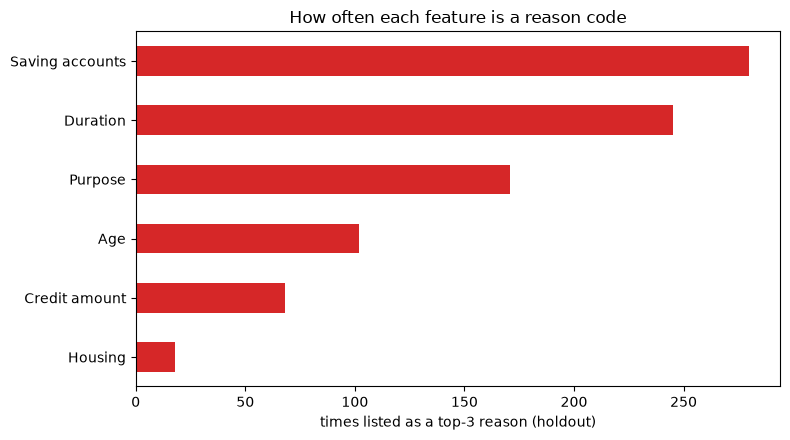

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
freq.sort_values().plot(kind="barh", ax=ax, color="tab:red")
ax.set_xlabel("times listed as a top-3 reason (holdout)")
ax.set_title("How often each feature is a reason code")
fig.tight_layout()
fig.savefig(FIG / "cr04_reason_frequency.png", dpi=120)
plt.show()

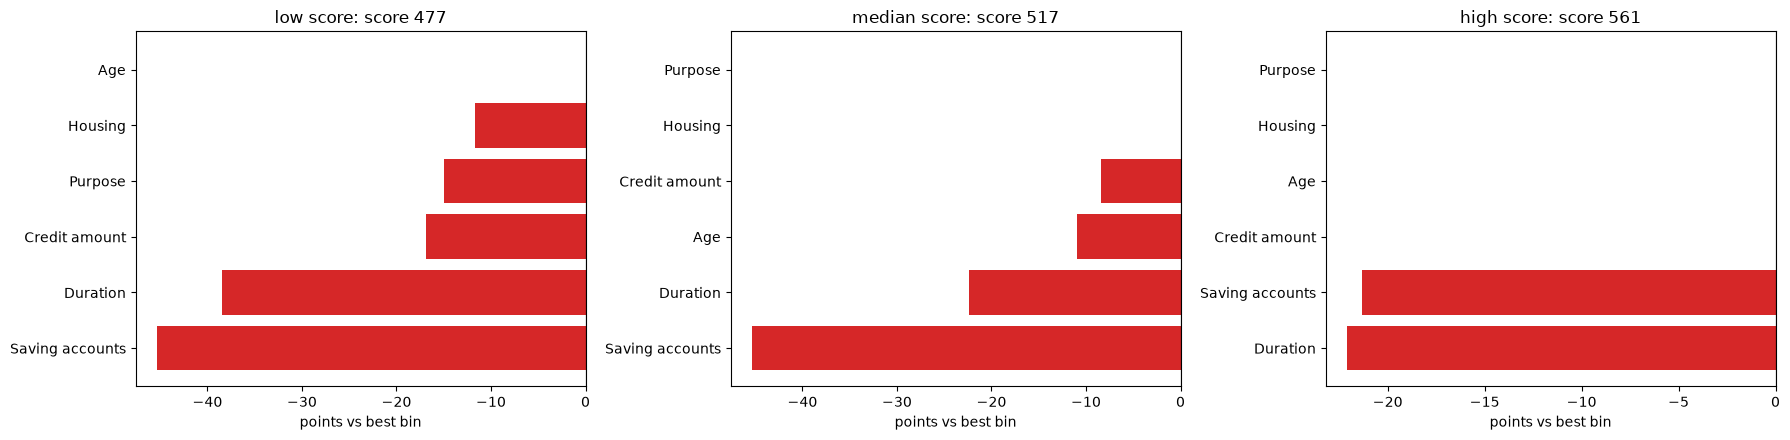

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, idx, label in zip(axes, picks, ["low score", "median score", "high score"]):
    plot_applicant(sc, X_hold.loc[[idx]], ax=ax)
    ax.set_title(f"{label}: score {score[idx]:.0f}")
fig.tight_layout()
fig.savefig(FIG / "cr04_applicant_points.png", dpi=120)
plt.show()

## 5. Summary

- Reason codes are generated for every holdout applicant. The automated check matches the
  independent recomputation for all of them (see section 2).
- The hand-checked cases are in section 3.
- SHAP for the LightGBM challenger (CR02) is not included yet. It needs the `shap` dependency,
  which the plan requires approval for.

In [8]:
codes.head(3)

,reason_1,reason_2,reason_3
80,Saving accounts,Duration,Credit amount
157,Saving accounts,Purpose,Duration
65,Purpose,Saving accounts,Duration
